# Empty-Car Hunting and Hollow Wear

Notebook 1 looked at the original files. Here I use the merged CSV to see whether differences between the left and right wheels of a wheelset are related to empty-car hunting. The merged data has one row per wheelset and rail profile. Hunting is recorded for the truck, which contains two wheelsets.

The data file goes in the project `data` folder. The chart and results in this notebook are for our internal analysis.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

data_folder = project_folder / "data"
data_path = data_folder / "final_merged_data.csv"
if not data_path.exists():
    data_path = data_folder / "final_merged_data(in).csv"

data = pd.read_csv(data_path)
print(f"Loaded {len(data)} wheelset/rail-profile rows from {data_path.name}.")

Loaded 392 wheelset/rail-profile rows from final_merged_data(in).csv.


## Check the rows we need

For this analysis, each car/truck/rail-profile group should have two wheelsets and one empty-car hunting result. I check that before comparing the wear measurements.

In [4]:
truck_key = ["Car", "Truck", "Rail_Profile"]
columns = truck_key + [
    "Axle", "Max Hollow Wear_L", "Max Hollow Wear_R", "Empty_Truck_Hunted"
]

if data[columns].isna().any().any():
    raise ValueError("One of the columns needed for this analysis has missing values.")

wheelset_counts = data.groupby(truck_key)["Axle"].nunique()
hunting_counts = data.groupby(truck_key)["Empty_Truck_Hunted"].nunique()

if (wheelset_counts != 2).any() or (hunting_counts != 1).any():
    raise ValueError("Check the wheelset counts or repeated hunting results.")

print(f"Truck/rail-profile assessments: {len(wheelset_counts)}")
print(f"Distinct trucks: {data[["Car", "Truck"]].drop_duplicates().shape[0]}")
print("Each assessment has two wheelsets and one hunting result.")

Truck/rail-profile assessments: 196
Distinct trucks: 28
Each assessment has two wheelsets and one hunting result.


## Compare the wheels within each wheelset

I take the absolute difference between the left and right `Max Hollow Wear` values. For each truck/rail assessment, I use the larger difference of its two wheelsets. That gives one feature for each truck outcome while keeping the wheelset as the starting point.

In [5]:
wheelsets = data[columns].copy()
wheelsets["left_right_difference"] = (
    wheelsets["Max Hollow Wear_L"] - wheelsets["Max Hollow Wear_R"]
).abs()

truck_results = (
    wheelsets.groupby(truck_key, as_index=False)
    .agg(
        largest_wheelset_difference=("left_right_difference", "max"),
        empty_car_hunted=("Empty_Truck_Hunted", "first"),
    )
)

summary = truck_results.groupby("empty_car_hunted")[
    "largest_wheelset_difference"
].agg(["count", "median"])
display(summary.rename(index={False: "No hunting recorded", True: "Hunting recorded"}))

,count,median
empty_car_hunted,,
No hunting recorded,70,1.2700
Hunting recorded,126,0.8911


## Look across rail profiles

Each truck appears under several rail profiles, so these are repeated assessments of the same trucks. The bars show medians for exploration; they are not independent samples or evidence of cause.

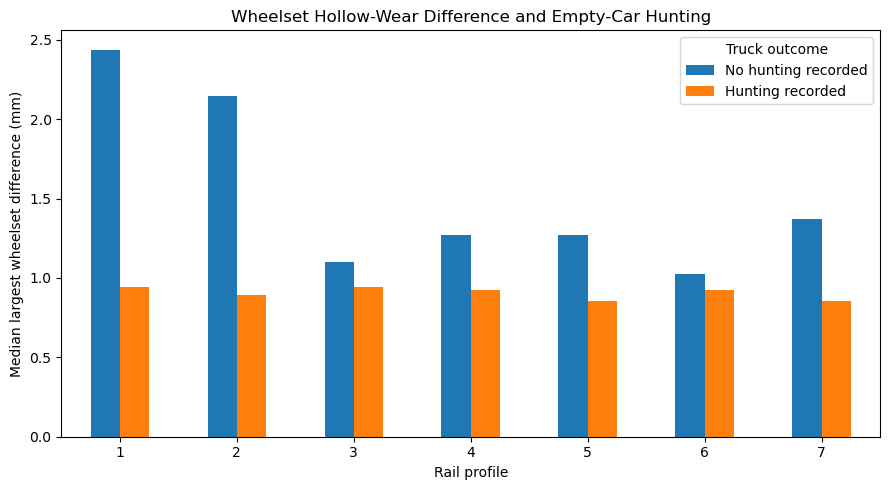

In [6]:
median_by_rail = (
    truck_results.groupby(["Rail_Profile", "empty_car_hunted"])[
        "largest_wheelset_difference"
    ]
    .median()
    .unstack()
    .rename(columns={False: "No hunting recorded", True: "Hunting recorded"})
)

ax = median_by_rail.plot.bar(figsize=(9, 5), rot=0)
ax.set_title("Wheelset Hollow-Wear Difference and Empty-Car Hunting")
ax.set_xlabel("Rail profile")
ax.set_ylabel("Median largest wheelset difference (mm)")
ax.legend(title="Truck outcome")
plt.tight_layout()
plt.show()

## What I found

The merged file has 392 wheelset/rail-profile rows, representing 196 truck/rail-profile assessments from 28 distinct trucks. Every assessment in this file has two wheelsets and one consistent empty-car hunting flag.

The median of the largest left/right wheelset difference is **1.27** when no hunting is recorded and **0.8911** when hunting is recorded. In this first comparison, a larger difference does **not** line up with more recorded hunting. The rail-profile plot lets us see whether that description changes across conditions.

One wheel has a reported `Max Hollow Wear_L` value of **19.774**, much higher than the other values I inspected. I kept it in the analysis, but we should check that measurement with the source file before interpreting the size of the difference. The merged file contains 28 trucks; the project overview mentions 29, so we should also check whether the unworn reference truck was intentionally left out.

**Next:** Confirm how `Empty_Truck_Hunted` was defined and what units the hollow-wear fields use. Then compare other wheelset features, including the amount of wear on each side, while keeping the repeated rail conditions and shared truck outcomes together. These are exploratory results, not evidence that wear differences cause hunting.